In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#function to load data
def load_data(path):
    df=pd.read_csv(path)#read the csv file
    print(df.head())#show first 5 rows so we see what the data looks like
    print(df.shape)# see how many rows and columns we have
    print(df.info())# check types of columns and non-empty counts
    print(df.isnull().sum())# check which columns have missing values
    return df

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
(1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
age         0
sex         0
bmi         0
children    0
smoker      0
region     

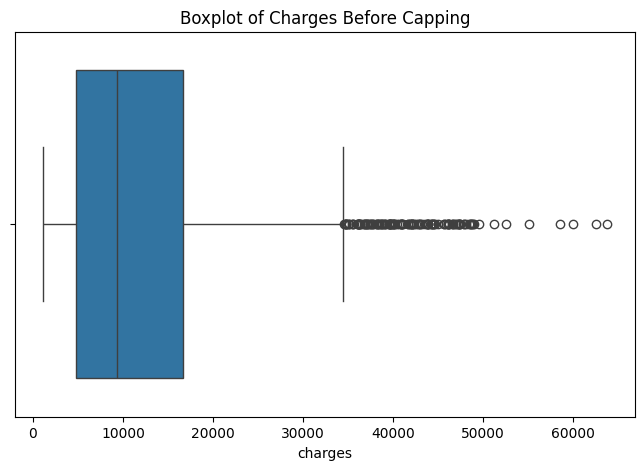

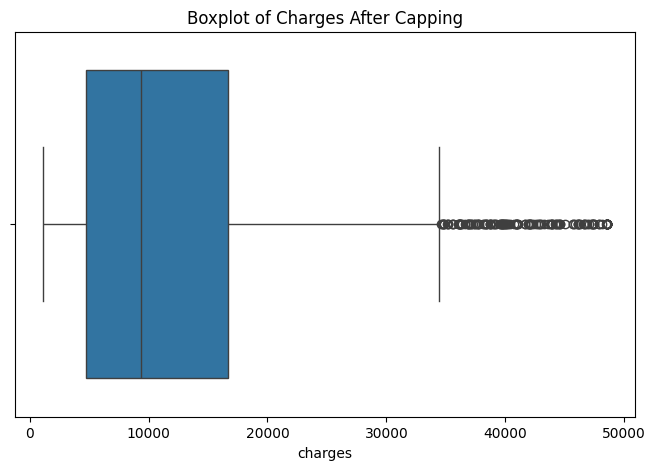


 we finally finished clean the dataa


In [ ]:
#function to clean data
def clean_data(df):
    # for text columns, use 'unknown'+ fill missing values
    df["sex"]=df["sex"].fillna("unknown")
    df["smoker"]=df["smoker"].fillna("unknown")
    df["region"]=df["region"].fillna("unknown")
    # for numbers, use median
    df["bmi"]=df["bmi"].fillna(df["bmi"].median())


    # change text columns to category type to save memory and make analysis easier+they have limited repeated values
    df["sex"]=df["sex"].astype("category")
    df["smoker"]=df["smoker"].astype("category")
    df["region"]=df["region"].astype("category")



    print(df.duplicated().sum())#check duplicates
    # remove duplicate rows because repeated rows can affect the analysis and give wrong results
    df=df.drop_duplicates()
    print(df.shape[0])# show number of rows left after removing duplicates to check changes



    # look at outliers in the charges column
    plt.figure(figsize=(8,5)) # create a figure of size 8x5 inches for the plot
    sns.boxplot(x=df["charges"])# draw a boxplot of the 'charges' column to see how charges look and check if there are very high value
    plt.title("Boxplot of Charges Before Capping")# add a title to the plot
    plt.show() # show the plot on the screen
    # i see some really high charges that are far from most value(outliers)



    # cap values bigger than 99th percentile to reduce the effect of extreme outliers on analysis
    q99 = df['charges'].quantile(0.99)
    df.loc[df['charges'] > q99, 'charges'] = q99


    # check the 'charges' column again after capping
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df['charges'])
    plt.title("Boxplot of Charges After Capping")
    plt.show()
    # after capping, the really high charges are smaller now the chart looks better


    assert df['charges'].isnull().sum() == 0 # no missing values left
    assert (df['charges'] > 0).all()  # all charges are positive
    assert df.shape[1] == 7 # make sure we have 7 columns
    print("\n we finally finished clean the dataa")
    return df

df_raw = load_data("/kaggle/input/datasets/eylanalqazlan/001-cleaning-ipynb/insurance.csv")
df = clean_data(df_raw)




